# GPU acceleration: NOAA and ERA5 weather experiments

This notebook reads the saved experiments for issue #42. **No GPU or downloaded weather store is needed to inspect these results.** The optional final cells can run a new experiment or a small GPU interface example.

The initial NOAA fields fit in VRAM. The later **native-float32 global ERA5 2018 field is 33.88 GiB**, exceeding both the 16 GiB RTX 3080 Laptop GPU and WSL's 13.58 GiB RAM limit. The machine has **32 GiB installed RAM**; WSL sees a smaller allocation. The timestamp subsets are 4.24 GiB and 16.94 GiB. Nothing was tiled, interpolated or promoted to float64 to inflate the data size.

See [`benchmarks/era5_results.md`](../benchmarks/era5_results.md) for the larger-than-VRAM findings and [`benchmarks/results.md`](../benchmarks/results.md) for the original NOAA tables. Acquisition and reproduction commands are in [`benchmarks/README.md`](../benchmarks/README.md). JSON reports retain settings, repetitions, failures, memory and quality measurements. This work does not implement the separate dtype-policy issue #25.


In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

repository = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "benchmarks/gpu_svd.py").is_file()
)
reports = {}
report_threads = {}
rows = []
for path in sorted((repository / "benchmarks/results").glob("*.json")):
    report = json.loads(path.read_text())
    if "environment" not in report or "results" not in report:
        continue
    reports[path.stem] = report
    env = report["environment"]
    threads = env.get("blas_threads", "1")
    report_threads[path.stem] = str(
        threads.get("OPENBLAS_NUM_THREADS", "1")
        if isinstance(threads, dict)
        else threads
    )
    for row in report["results"]:
        input_bytes = int(np.prod(env["shape"])) * np.dtype(row["dtype"]).itemsize
        rows.append(
            dict(
                row,
                experiment=path.stem,
                input_GiB=input_bytes / 1024**3,
                BLAS_threads=report_threads[path.stem],
                repetitions=env["repeats"],
                iterator=row.get("iterator", env.get("iterator", "power")),
                captured_energy_fraction=row.get("captured_energy_fraction"),
                copy_clock=(
                    "pre/post sync"
                    if "before and after" in env.get("transfer_timing", "")
                    else "post-upload sync estimate"
                ),
            )
        )
measurements = pd.DataFrame(rows)
successful = measurements.loc[measurements["status"] == "ok"].copy()
print(f"Loaded {len(measurements)} recorded cases from {len(reports)} reports.")
display(
    pd.DataFrame(
        [
            {
                "report": name,
                "shape": report["environment"]["shape"],
                "BLAS threads": report_threads[name],
                "repetitions": report["environment"]["repeats"],
                "cases": len(report["results"]),
            }
            for name, report in reports.items()
        ]
    )
)

Loaded 76 recorded cases from 14 reports.


,report,shape,BLAS threads,repetitions,cases
0,era5-2018-2hourly-svd,"[1038240, 4380]",8,1,4
1,era5-2018-8hourly-qr-svd,"[1038240, 1095]",8,1,2
2,era5-2018-8hourly-svd,"[1038240, 1095]",8,3,8
3,era5-2018-copy-timing-check,"[1038240, 8760]",8,1,2
4,era5-2018-cpu-thread-calibration,"[1038240, 1095]",1,3,1
5,era5-2018-hourly-public-pod,"[1038240, 8760]",8,1,2
6,era5-2018-hourly-public-svd,"[1038240, 8760]",8,1,2
7,era5-2018-hourly-svd,"[1038240, 8760]",8,3,4
8,era5-2018-persistence-budget,"[1038240, 8760]",8,1,4
9,era5-2018-staged-gate,"[1038240, 8760]",8,1,2


## CPU/GPU wall times

Pairings stay within the same report and settings. Values are median seconds; **a report with one repetition is an exploratory observation**, not a repeatability measurement. CPU thread settings are explicit because the initial eight-thread ERA5 baseline and the thread-calibration experiment must be distinguished.

Disk-backed timings include reads, copies and CPU outputs, with an uncontrolled OS filesystem cache. Persisted timings exclude persistence setup. Larger fields stay disk-backed. Full-scale ERA5 uses staged execution; ordinary shared input graphs can exhaust memory even without `.persist()`.


In [2]:
index = [
    "experiment",
    "BLAS_threads",
    "repetitions",
    "dtype",
    "residency",
    "algorithm",
    "n_power_iter",
    "iterator",
]
comparison = successful.pivot(
    index=index, columns="backend", values="seconds_median"
).reset_index()
comparison.columns.name = None
comparison["CPU/GPU speedup"] = comparison["numpy"] / comparison["cupy"]
display(comparison.round(4))

,experiment,BLAS_threads,repetitions,dtype,residency,algorithm,n_power_iter,iterator,cupy,numpy,CPU/GPU speedup
0,era5-2018-2hourly-svd,8,1,float32,disk,randomized,0,QR,31.6325,60.5503,1.9142
1,era5-2018-2hourly-svd,8,1,float32,disk,randomized,2,QR,85.3541,165.6183,1.9404
2,era5-2018-8hourly-qr-svd,8,1,float32,disk,randomized,2,QR,20.9368,45.8640,2.1906
3,era5-2018-8hourly-svd,8,3,float32,disk,randomized,0,power,7.6931,16.3923,2.1308
4,era5-2018-8hourly-svd,8,3,float32,disk,randomized,2,power,20.5863,42.6979,2.0741
5,era5-2018-8hourly-svd,8,3,float32,persisted,randomized,0,power,0.4090,10.8875,26.6203
6,era5-2018-8hourly-svd,8,3,float32,persisted,randomized,2,power,0.6470,26.8713,41.5353
7,era5-2018-copy-timing-check,8,1,float32,disk,randomized,0,QR,85.8682,NaN,NaN
8,era5-2018-copy-timing-check,8,1,float32,disk,randomized,2,QR,261.2651,NaN,NaN
9,era5-2018-cpu-thread-calibration,1,3,float32,persisted,randomized,0,power,NaN,13.8461,NaN


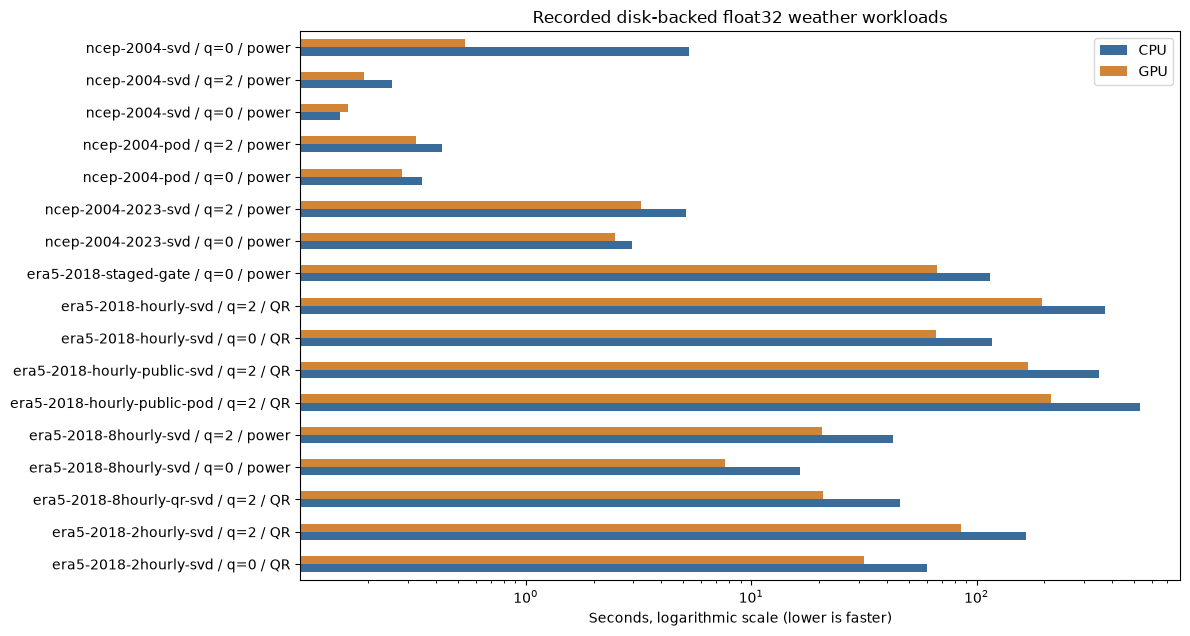

In [3]:
plot_data = (
    comparison.loc[
        (comparison["dtype"] == "float32") & (comparison["residency"] == "disk")
    ]
    .dropna(subset=["numpy", "cupy"])
    .copy()
)
plot_data["case"] = (
    plot_data["experiment"]
    + " / q="
    + plot_data["n_power_iter"].astype(str)
    + " / "
    + plot_data["iterator"]
)
ax = (
    plot_data.set_index("case")[["numpy", "cupy"]]
    .rename(columns={"numpy": "CPU", "cupy": "GPU"})
    .plot.barh(
        figsize=(12, max(5, len(plot_data) * 0.38)), color=["#396b9b", "#d18538"]
    )
)
ax.set_xscale("log")
ax.set_xlabel("Seconds, logarithmic scale (lower is faster)")
ax.set_ylabel("")
ax.set_title("Recorded disk-backed float32 weather workloads")
plt.tight_layout()
plt.show()

## Transfer time and persistence

Raw Dask runs synchronize copies to measure transfer windows. The early reports synchronized after upload; queued work could contribute to those estimates. The supplemental full-year transfer check synchronizes before and after each copy. The clock column distinguishes them. This instrumentation is not a fully overlapped implementation. Public SVD/POD internal transfer timings are `null`, because only their total wall time is instrumented. GPU memory is sampled device-wide every 10 ms, including workspace and other processes; brief peaks may be missed. Persistence setup is reported separately from fit time.


In [4]:
copies = successful.loc[
    (successful["backend"] == "cupy") & (successful["model"] == "dask-svd")
].copy()
copies["copy_percent"] = (
    100
    * (copies["upload_seconds_median"] + copies["download_seconds_median"])
    / copies["seconds_median"]
)
copies["peak_GPU_GiB"] = copies["peak_gpu_bytes_sampled"] / 1024**3
display(
    copies[
        [
            "experiment",
            "copy_clock",
            "dtype",
            "residency",
            "n_power_iter",
            "iterator",
            "seconds_median",
            "persist_seconds",
            "upload_seconds_median",
            "download_seconds_median",
            "copy_percent",
            "peak_GPU_GiB",
        ]
    ].round(3)
)

,experiment,copy_clock,dtype,residency,n_power_iter,iterator,seconds_median,persist_seconds,upload_seconds_median,download_seconds_median,copy_percent,peak_GPU_GiB
2,era5-2018-2hourly-svd,post-upload sync estimate,float32,disk,0,QR,31.632,0.000,9.591,0.044,30.459,3.979
3,era5-2018-2hourly-svd,post-upload sync estimate,float32,disk,2,QR,85.354,0.000,26.493,0.030,31.074,3.979
5,era5-2018-8hourly-qr-svd,post-upload sync estimate,float32,disk,2,QR,20.937,0.000,6.240,0.020,29.898,3.264
10,era5-2018-8hourly-svd,post-upload sync estimate,float32,disk,0,power,7.693,0.000,2.130,0.026,28.026,3.264
11,era5-2018-8hourly-svd,post-upload sync estimate,float32,disk,2,power,20.586,0.000,6.436,0.022,31.369,3.264
12,era5-2018-8hourly-svd,post-upload sync estimate,float32,persisted,0,power,0.409,3.357,0.000,0.028,6.890,7.624
13,era5-2018-8hourly-svd,post-upload sync estimate,float32,persisted,2,power,0.647,3.218,0.000,0.021,3.244,7.624
14,era5-2018-copy-timing-check,pre/post sync,float32,disk,0,QR,85.868,0.000,24.170,0.100,28.264,5.016
15,era5-2018-copy-timing-check,pre/post sync,float32,disk,2,QR,261.265,0.000,72.799,0.097,27.901,5.016
23,era5-2018-hourly-svd,post-upload sync estimate,float32,disk,0,QR,65.957,0.000,19.092,0.088,29.080,5.133


## Evidence of execution beyond memory capacity

The decoded hourly field is larger than both relevant memory capacities. The table shows input size alongside sampled process RSS and GPU allocation, rather than treating a chunk size as proof that the algorithm streams. The 10 GiB CuPy pool cap excludes some driver/workspace allocations. Host execution has an 8 GiB RSS abort budget checked between tasks. Neither guard implements spilling.


,experiment,backend,n_power_iter,iterator,input_GiB,host_RSS_GiB,GPU_GiB,seconds_median
0,era5-2018-2hourly-svd,numpy,0,QR,16.941,2.515,NaN,60.550
1,era5-2018-2hourly-svd,numpy,2,QR,16.941,2.625,NaN,165.618
2,era5-2018-2hourly-svd,cupy,0,QR,16.941,1.236,3.979,31.632
3,era5-2018-2hourly-svd,cupy,2,QR,16.941,1.259,3.979,85.354
14,era5-2018-copy-timing-check,cupy,0,QR,33.881,1.171,5.016,85.868
15,era5-2018-copy-timing-check,cupy,2,QR,33.881,1.044,5.016,261.265
17,era5-2018-hourly-public-pod,numpy,2,QR,33.881,2.564,NaN,531.059
18,era5-2018-hourly-public-pod,cupy,2,QR,33.881,1.012,5.034,212.827
19,era5-2018-hourly-public-svd,numpy,2,QR,33.881,2.661,NaN,348.575
20,era5-2018-hourly-public-svd,cupy,2,QR,33.881,1.121,5.016,169.167


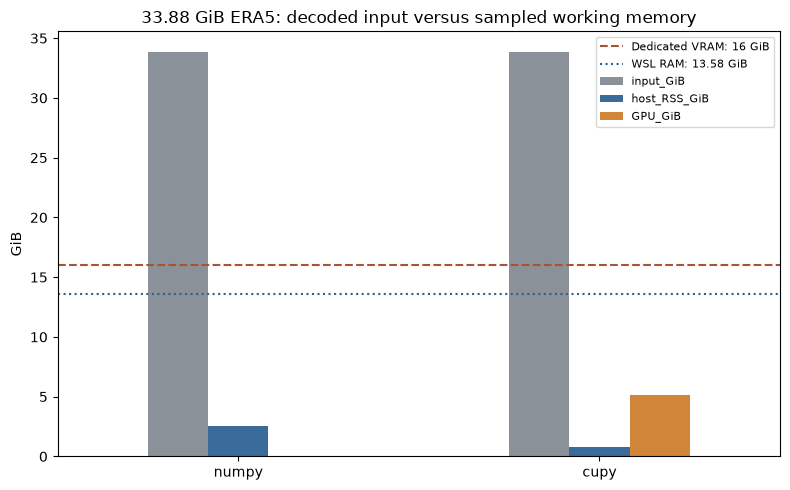

In [5]:
proof = successful.loc[successful["input_GiB"] > 16].copy()
proof["host_RSS_GiB"] = proof["peak_host_rss_bytes_sampled"] / 1024**3
proof["GPU_GiB"] = proof["peak_gpu_bytes_sampled"] / 1024**3
display(
    proof[
        [
            "experiment",
            "backend",
            "n_power_iter",
            "iterator",
            "input_GiB",
            "host_RSS_GiB",
            "GPU_GiB",
            "seconds_median",
        ]
    ].round(3)
)

headline = proof.loc[
    (proof["experiment"] == "era5-2018-hourly-svd") & (proof["n_power_iter"] == 2)
].copy()
if not headline.empty:
    ax = headline.set_index("backend")[
        ["input_GiB", "host_RSS_GiB", "GPU_GiB"]
    ].plot.bar(figsize=(8, 5), color=["#8b9198", "#396b9b", "#d18538"], rot=0)
    ax.axhline(16, color="#a55532", linestyle="--", label="Dedicated VRAM: 16 GiB")
    ax.axhline(13.58, color="#315f88", linestyle=":", label="WSL RAM: 13.58 GiB")
    ax.set_ylabel("GiB")
    ax.set_xlabel("")
    ax.set_title("33.88 GiB ERA5: decoded input versus sampled working memory")
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.savefig(repository / "benchmarks/results/era5-memory.png", dpi=160)
    plt.show()

## Approximation quality, failures and skips

Sample RMSE is in kelvin, measured on eight evenly spaced snapshots outside fit timing. The relative error of uncentred temperatures is divided by a large mean field, so also inspect RMSE and the centred POD energy fraction. Different NumPy/CuPy random streams produce different approximations despite an equal seed.

The native-float32 control showed that ordinary power iterations could **worsen** reconstruction. The additional `iterator="QR"` experiments use Dask's existing stabilization option, without changing precision or the library's iterator default. Retained failures and persistence skips are shown explicitly below.


In [6]:
quality = successful.loc[successful["validation"].notna()].copy()
quality["sample_RMSE_K"] = quality["validation"].map(lambda value: value["rmse"])
quality["relative_L2_error"] = quality["validation"].map(
    lambda value: value["relative_l2_error"]
)
display(
    quality[
        [
            "experiment",
            "backend",
            "residency",
            "n_power_iter",
            "iterator",
            "sample_RMSE_K",
            "relative_L2_error",
            "captured_energy_fraction",
        ]
    ].round(6)
)
display(
    measurements.loc[
        measurements["status"] != "ok",
        ["experiment", "backend", "residency", "status", "reason"],
    ]
)

,experiment,backend,residency,n_power_iter,iterator,sample_RMSE_K,relative_L2_error,captured_energy_fraction
0,era5-2018-2hourly-svd,numpy,disk,0,QR,2.994135,0.010705,NaN
1,era5-2018-2hourly-svd,numpy,disk,2,QR,2.442328,0.008732,NaN
2,era5-2018-2hourly-svd,cupy,disk,0,QR,2.933728,0.010489,NaN
3,era5-2018-2hourly-svd,cupy,disk,2,QR,2.430437,0.008689,NaN
4,era5-2018-8hourly-qr-svd,numpy,disk,2,QR,2.407041,0.008607,NaN
5,era5-2018-8hourly-qr-svd,cupy,disk,2,QR,2.394712,0.008563,NaN
6,era5-2018-8hourly-svd,numpy,disk,0,power,2.867606,0.010255,NaN
7,era5-2018-8hourly-svd,numpy,disk,2,power,4.613523,0.016498,NaN
8,era5-2018-8hourly-svd,numpy,persisted,0,power,2.867606,0.010255,NaN
9,era5-2018-8hourly-svd,numpy,persisted,2,power,4.613523,0.016498,NaN


,experiment,backend,residency,status,reason
25,era5-2018-persistence-budget,numpy,persisted,skipped,Input exceeds the host persistence budget.
26,era5-2018-persistence-budget,numpy,persisted,skipped,Input exceeds the host persistence budget.
27,era5-2018-persistence-budget,cupy,persisted,skipped,Input exceeds persistence budget; use the disk...
28,era5-2018-persistence-budget,cupy,persisted,skipped,Input exceeds persistence budget; use the disk...
31,era5-2018-unstaged-diagnostic,cupy,disk,error,OutOfMemoryError: Out of memory allocating 498...


## Implementation and scope

`svdrom.config.set(array_backend="cupy")` delegates to Dask. `TruncatedSVD`, POD and StandardScaler compute on GPU chunks. Public eager results and stored statistics stay NumPy-backed; deferred outputs stay lazy and download final chunks before gathering. GPU randomized SVD/POD default to Dask's staged `compute=True`, with an explicit `compute=False` override. This staging option is separate from the flags controlling output laziness.

Full-scale covariance POD would require about 7.84 TiB just for its float64 spatial covariance matrix, so it is validated on small GPU test fixtures. The NOAA experiments cover TSQR; full temporal TSQR is not claimed for global ERA5. OptDMD keeps its CPU solver and warns under CuPy. Multiple GPUs, spilling, GPU CI infrastructure, Hankel acceleration and a dtype policy remain outside scope.

Results are local on `implement/cupy`. The Markdown tables are ready to review, but no issue comment or PR has been published.

## Run a new ERA5 benchmark

This is disabled by default and can take several minutes per case. It writes a new report under `/tmp` and retains the saved results above.


In [7]:
RUN_BENCHMARK = False
DATASET = repository / "demos/data/gpu/era5-2018-hourly.zarr"
MODEL = "svdrom-pod"  # or dask-svd / svdrom-svd

if RUN_BENCHMARK:
    import os
    import subprocess
    import sys

    subprocess.run(
        [
            sys.executable,
            str(repository / "benchmarks/gpu_svd.py"),
            str(DATASET),
            "--variable",
            "2m_temperature",
            "--model",
            MODEL,
            "--dtype",
            "float32",
            "--rank",
            "20",
            "--spatial-chunk",
            "-1",
            "--time-chunk",
            "32",
            "--algorithm",
            "randomized-0",
            "randomized-2",
            "--iterator",
            "QR",
            "--staged",
            "--residency",
            "disk",
            "--host-memory-limit",
            "8 GiB",
            "--device-memory-limit",
            "10 GiB",
            "--validation-snapshots",
            "8",
            "--warmups",
            "0",
            "--repeats",
            "1",
            "--output",
            "/tmp/svdrom-notebook-era5-results.json",
        ],
        env=dict(os.environ, OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1"),
        check=True,
    )
else:
    print("Saved results loaded; live benchmarking is disabled.")

Saved results loaded; live benchmarking is disabled.


## Inspect lazy CPU outputs on a GPU

This small synthetic example checks the interface, independently of the real-data benchmarks. It requires working CUDA and CuPy. Its deferred factors must materialize as NumPy arrays even after the backend context ends.


In [8]:
RUN_GPU_EXAMPLE = False

if RUN_GPU_EXAMPLE:
    import cupy as cp
    import dask
    import dask.array as da
    import numpy as np
    import xarray as xr

    from svdrom import TruncatedSVD

    if not cp.is_available():
        message = "A usable NVIDIA GPU and CUDA runtime are required."
        raise RuntimeError(message)
    rng = np.random.default_rng(42)
    sample = xr.DataArray(
        da.from_array(
            rng.normal(size=(64, 3)) @ rng.normal(size=(3, 24)), chunks=(16, 6)
        ),
        dims=("space", "time"),
    )
    with dask.config.set({"array.backend": "cupy"}):
        model = TruncatedSVD(
            3,
            algorithm="randomized",
            compute_u=False,
            compute_v=False,
            compute_var_ratio=False,
        ).fit(sample, seed=42)
    print("Deferred left vectors:", type(model.u.data).__name__)
    model.compute_u()
    model.compute_v()
    model.compute_var_ratio()
    print(
        "Computed factor backends:",
        type(model.u.data),
        type(model.s),
        type(model.v.data),
    )
    np.testing.assert_allclose(
        model.reconstruct().to_numpy(),
        sample.to_numpy(),
        atol=1e-10,
        err_msg="Expected reconstruction to match the synthetic low-rank input.",
    )
else:
    print("Set RUN_GPU_EXAMPLE=True to inspect deferred output conversion on your GPU.")

Set RUN_GPU_EXAMPLE=True to inspect deferred output conversion on your GPU.
